<div style="height: 50px; background: linear-gradient(to right, #e9d5ff, #a855f7, #6b21a8);"></div>

👨‍💻 **The machine learning models used in this project are:** 
1. Linear Logistic Regression
2. Linear Support Vector Machine (SVM)
3. K Neighbours
4. Naive Bayes (Categorical & Gaussian)
5. Decision Tree
6. Random Forest


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Reading Data Set 👓
👉 After importing libraries, we will also **import the dataset** that will be used.

In [3]:
df = pd.read_excel("cardio_data_ml.xlsx", parse_dates=['date'])
display(df.head())

,date,country,id,active,age_group,alco,ap_hi,ap_lo,cholesterol,gender,gluc,height,occupation,smoke,weight,pca,disease
0,2021-05-03,Indonesia,0,1,5,0,110,80,1,2,1,168,Architect,0,62.0,0.9108,0
1,2021-08-05,Malaysia,1,1,5,0,140,90,3,1,1,156,Accountant,0,85.0,0.9380,1
2,2022-11-13,Indonesia,2,0,5,0,130,70,3,1,1,165,Chef,0,64.0,0.9190,1
3,2018-10-31,Singapore,3,1,4,0,150,100,1,2,1,169,Lawyer,0,82.0,0.7938,1
4,2020-09-25,Singapore,4,0,4,0,100,60,1,1,1,156,Architect,0,56.0,0.7346,0


In [4]:
dfx = df.copy()

In [5]:
#dfx = df.select_dtypes(include=np.number)
dfx.drop(columns=['id', 'date'], inplace=True)

## Categorical Variables 📊

In [6]:
dfx.disease.value_counts()

disease
0    35021
1    34979
Name: count, dtype: int64

## Numerical Variables 🔢

In [7]:
dfx.describe().round(4)

,active,age_group,alco,ap_hi,ap_lo,cholesterol,gender,gluc,height,smoke,weight,pca,disease
count,70000.0000,70000.0000,70000.0000,70000.0000,70000.0000,70000.0000,70000.0000,70000.0000,70000.0000,70000.0000,70000.0000,70000.0000,70000.0000
mean,0.8037,4.8551,0.0538,126.8483,82.9645,1.3669,1.3496,1.2265,164.3592,0.0881,74.2057,0.9053,0.4997
std,0.3972,0.7402,0.2256,17.4309,16.8249,0.6803,0.4768,0.5723,8.2101,0.2835,14.3958,0.1215,0.5000
min,0.0000,2.0000,0.0000,60.0000,40.0000,1.0000,1.0000,1.0000,55.0000,0.0000,10.0000,0.4208,0.0000
25%,1.0000,4.0000,0.0000,120.0000,80.0000,1.0000,1.0000,1.0000,159.0000,0.0000,65.0000,0.7808,0.0000
50%,1.0000,5.0000,0.0000,120.0000,80.0000,1.0000,1.0000,1.0000,165.0000,0.0000,72.0000,0.9178,0.0000
75%,1.0000,5.0000,0.0000,140.0000,90.0000,2.0000,2.0000,1.0000,170.0000,0.0000,82.0000,0.9514,1.0000
max,1.0000,6.0000,1.0000,200.0000,200.0000,3.0000,2.0000,3.0000,250.0000,1.0000,200.0000,1.2577,1.0000


In [8]:
skewRooms = df.disease.skew(axis = 0, skipna = True)
print('disease skewness: ', skewRooms)

disease skewness:  0.0012000259309944698


C:\Users\kiank\AppData\Local\Temp\ipykernel_20348\386864395.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['disease']);


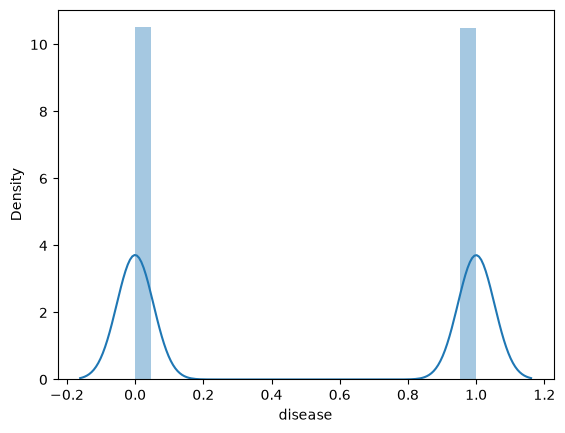

In [9]:
sns.distplot(df['disease']);

# Dataset Preparation ⚙
👉 This section will prepare the dataset before building the machine learning models.

## Feature Engineering 🔧
👉 The FE method that used is **one-hot encoding**, which is **transforming categorical variables into a form that could be provided to ML algorithms to do a better prediction**.

In [10]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# Initialize LabelEncoder for label encoding
label_encoder = LabelEncoder()

# Apply label encoding to the 'Residential' column
dfx['age_group'] = label_encoder.fit_transform(dfx['age_group'])
dfx['cholesterol'] = label_encoder.fit_transform(dfx['cholesterol'])
dfx['gluc'] = label_encoder.fit_transform(dfx['gluc'])

In [11]:
dfx = pd.get_dummies(dfx)

In [12]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Initialize StandardScaler for Z-score normalization
scaler_zscore = StandardScaler()

# Apply Z-score normalization to the data
#dfx = df.copy()
#dfx.drop(columns=['date', 'country', 'id', 'occupation'], inplace=True)

dfx[['height', 'weight']] = pd.DataFrame(scaler_zscore.fit_transform(dfx[['height', 'weight']]), columns=['height', 'weight'])
# Naive Bayes (Gaussian) cannot take negative values
dfx[['height']] = dfx[['height']] - dfx.height.describe().min()
dfx[['weight']] = dfx[['weight']] - dfx.weight.describe().min()
dfx.head()

,active,age_group,alco,ap_hi,ap_lo,cholesterol,gender,gluc,height,smoke,...,country_Singapore,occupation_Accountant,occupation_Architect,occupation_Chef,occupation_Doctor,occupation_Engineer,occupation_Lawyer,occupation_Nurse,occupation_Others,occupation_Teacher
0,1,3,0,110,80,0,2,0,13.763589,0,...,False,False,True,False,False,False,False,False,False,False
1,1,3,0,140,90,2,1,0,12.301969,0,...,False,True,False,False,False,False,False,False,False,False
2,0,3,0,130,70,2,1,0,13.398184,0,...,False,False,False,True,False,False,False,False,False,False
3,1,2,0,150,100,0,2,0,13.885391,0,...,True,False,False,False,False,False,True,False,False,False
4,0,2,0,100,60,0,1,0,12.301969,0,...,True,False,True,False,False,False,False,False,False,False


## Use z-score to detect outlier on height

In [13]:
from scipy import stats

# Calculate z-scores for outlier detection
z_scores = np.abs(stats.zscore(dfx['height']))

# Set a threshold for z-score outliers (e.g., z-score > 2)
threshold = 2

# Identify outliers using z-score method
outliers_zscore = dfx[np.abs(z_scores) > threshold]

print("Data with outliers detected using z-score method:")
print(outliers_zscore)

Data with outliers detected using z-score method:
       active  age_group  alco  ap_hi  ap_lo  cholesterol  gender  gluc  \
14          1          1     1    130     90            0       2     0   
62          1          3     1    130     90            0       2     0   
76          1          3     0    120     80            0       2     0   
94          1          2     0    133     89            1       2     2   
103         1          2     0    125     80            0       2     2   
...       ...        ...   ...    ...    ...          ...     ...   ...   
69895       1          3     0    160    200            0       1     0   
69906       1          2     1    160    200            2       2     1   
69907       1          4     0    130    200            1       1     0   
69930       1          4     1    150    200            1       2     0   
69962       1          3     0    140    200            0       2     0   

          height  smoke  ...  country_Singapore  

In [14]:
# Keep rows that are NOT outliers
dfx = dfx[z_scores <= threshold].copy()

# Check the result
print("Data shape after removing outliers:", dfx.shape)


Data shape after removing outliers: (67665, 26)


## Use z-score to detect outlier on weight

In [15]:
from scipy import stats

# Calculate z-scores for outlier detection
z_scores = np.abs(stats.zscore(dfx['weight']))

# Set a threshold for z-score outliers (e.g., z-score > 2)
threshold = 2

# Identify outliers using z-score method
outliers_zscore = dfx[np.abs(z_scores) > threshold]

print("Data with outliers detected using z-score method:")
print(outliers_zscore)

Data with outliers detected using z-score method:
       active  age_group  alco  ap_hi  ap_lo  cholesterol  gender  gluc  \
15          0          2     0    120     80            0       2     0   
23          1          4     0    110     60            0       2     0   
30          1          3     0    120     80            2       1     0   
46          1          2     0    150     90            1       1     0   
83          1          3     0    160     90            0       1     0   
...       ...        ...   ...    ...    ...          ...     ...   ...   
69986       1          2     0    200    200            0       2     0   
69989       1          3     0    200    200            2       2     0   
69991       1          3     0    200     40            0       1     0   
69998       1          3     0    200    200            0       2     0   
69999       1          2     0    200     40            0       1     0   

          height  smoke  ...  country_Singapore  

In [16]:
# Keep rows that are NOT outliers
dfx = dfx[z_scores <= threshold].copy()

# Check the result
print("Data shape after removing outliers:", dfx.shape)


Data shape after removing outliers: (64796, 26)


In [17]:
dfx.describe().round(4)

,active,age_group,alco,ap_hi,ap_lo,cholesterol,gender,gluc,height,smoke,weight,pca,disease
count,64796.0000,64796.0000,64796.0000,64796.0000,64796.0000,64796.000,64796.0000,64796.0000,64796.0000,64796.0000,64796.0000,64796.0000,64796.0000
mean,0.8048,2.8553,0.0517,126.4109,82.6686,0.356,1.3405,0.2198,13.3001,0.0851,4.3508,0.9047,0.4925
std,0.3963,0.7391,0.2215,17.1035,16.4103,0.672,0.4739,0.5659,0.8556,0.2791,0.8059,0.1213,0.4999
min,0.0000,0.0000,0.0000,60.0000,40.0000,0.000,1.0000,0.0000,11.3276,0.0000,2.5008,0.4208,0.0000
25%,1.0000,2.0000,0.0000,120.0000,80.0000,0.000,1.0000,0.0000,12.6674,0.0000,3.8206,0.7806,0.0000
50%,1.0000,3.0000,0.0000,120.0000,80.0000,0.000,1.0000,0.0000,13.3982,0.0000,4.2374,0.9178,0.0000
75%,1.0000,3.0000,0.0000,140.0000,90.0000,0.000,2.0000,0.0000,13.8854,0.0000,4.8626,0.9508,1.0000
max,1.0000,4.0000,1.0000,200.0000,200.0000,2.000,2.0000,2.0000,15.2252,1.0000,6.3908,1.2577,1.0000


## Splitting the dataset 🪓
👉 The dataset will be split into **70% training and 30% testing**.

In [18]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [19]:
X = dfx.drop(["disease"], axis=1)
y = dfx["disease"]

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 0)

In [20]:
X_train.head()

,active,age_group,alco,ap_hi,ap_lo,cholesterol,gender,gluc,height,smoke,...,country_Singapore,occupation_Accountant,occupation_Architect,occupation_Chef,occupation_Doctor,occupation_Engineer,occupation_Lawyer,occupation_Nurse,occupation_Others,occupation_Teacher
43291,1,3,0,170,100,1,1,0,12.789176,0,...,False,False,False,False,True,False,False,False,False,False
25936,1,3,0,120,80,0,1,0,12.789176,0,...,False,False,False,False,False,True,False,False,False,False
7112,1,3,0,160,100,1,1,1,14.372598,0,...,True,False,False,False,False,False,False,False,True,False
3970,1,3,0,120,80,0,2,0,13.763589,0,...,False,False,False,False,True,False,False,False,False,False
32988,1,3,0,130,80,0,1,0,13.032779,1,...,False,False,False,False,False,False,True,False,False,False


In [21]:
X_test.head()

,active,age_group,alco,ap_hi,ap_lo,cholesterol,gender,gluc,height,smoke,...,country_Singapore,occupation_Accountant,occupation_Architect,occupation_Chef,occupation_Doctor,occupation_Engineer,occupation_Lawyer,occupation_Nurse,occupation_Others,occupation_Teacher
65449,1,3,1,80,120,2,2,2,12.789176,1,...,True,False,False,False,False,False,True,False,False,False
47054,1,3,0,150,90,0,2,0,13.398184,0,...,True,False,False,False,False,True,False,False,False,False
33576,1,2,0,110,69,0,2,0,14.616201,0,...,True,False,True,False,False,False,False,False,False,False
10172,1,3,0,120,60,0,2,0,14.250796,0,...,False,False,False,False,False,False,False,False,False,True
13840,0,4,0,130,80,2,1,0,14.250796,0,...,False,True,False,False,False,False,False,False,False,False


<div style="height: 50px; background: linear-gradient(to right, lightblue, blue, darkblue);"></div>

# Models 🛠

## 1. Logistic Regression

              precision    recall  f1-score   support

           0       0.70      0.79      0.74      9826
           1       0.75      0.65      0.70      9613

    accuracy                           0.72     19439
   macro avg       0.73      0.72      0.72     19439
weighted avg       0.73      0.72      0.72     19439



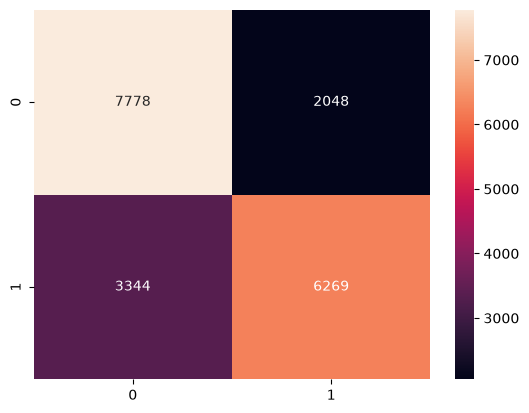

Logistic Regression accuracy is: 72.26%


In [22]:
from sklearn.linear_model import LogisticRegression
LRclassifier = LogisticRegression(solver='liblinear', max_iter=5000)
LRclassifier.fit(X_train, y_train)

y_pred = LRclassifier.predict(X_test)

print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='.0f')
plt.show()

from sklearn.metrics import accuracy_score
LRAcc = accuracy_score(y_pred,y_test)
print('Logistic Regression accuracy is: {:.2f}%'.format(LRAcc*100))

## 2. K Neighbours

              precision    recall  f1-score   support

           0       0.69      0.82      0.75      9826
           1       0.77      0.62      0.69      9613

    accuracy                           0.72     19439
   macro avg       0.73      0.72      0.72     19439
weighted avg       0.73      0.72      0.72     19439



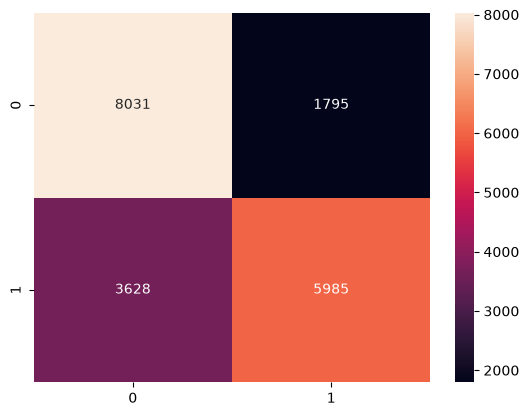

K Neighbours accuracy is: 72.10%


In [23]:
from sklearn.neighbors import KNeighborsClassifier
KNclassifier = KNeighborsClassifier(n_neighbors=20)
KNclassifier.fit(X_train, y_train)

y_pred = KNclassifier.predict(X_test)

print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='.0f')
plt.show()

from sklearn.metrics import accuracy_score
KNAcc = accuracy_score(y_pred,y_test)
print('K Neighbours accuracy is: {:.2f}%'.format(KNAcc*100))

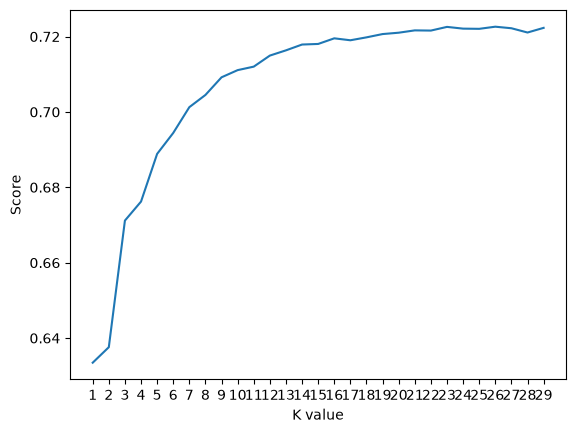

KNN Acc Max 72.26%


In [24]:
scoreListknn = []
for i in range(1,30):
    KNclassifier = KNeighborsClassifier(n_neighbors = i)
    KNclassifier.fit(X_train, y_train)
    scoreListknn.append(KNclassifier.score(X_test, y_test))
    
plt.plot(range(1,30), scoreListknn)
plt.xticks(np.arange(1,30,1))
plt.xlabel("K value")
plt.ylabel("Score")
plt.show()
KNAccMax = max(scoreListknn)
print("KNN Acc Max {:.2f}%".format(KNAccMax*100))

## 3. Support Vector Machine (SVM)

C:\Users\kiank\anaconda3\Lib\site-packages\sklearn\svm\_base.py:340: ConvergenceWarning: Solver terminated early (max_iter=251).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


              precision    recall  f1-score   support

           0       0.17      0.09      0.12      9826
           1       0.38      0.56      0.45      9613

    accuracy                           0.32     19439
   macro avg       0.27      0.33      0.28     19439
weighted avg       0.27      0.32      0.28     19439



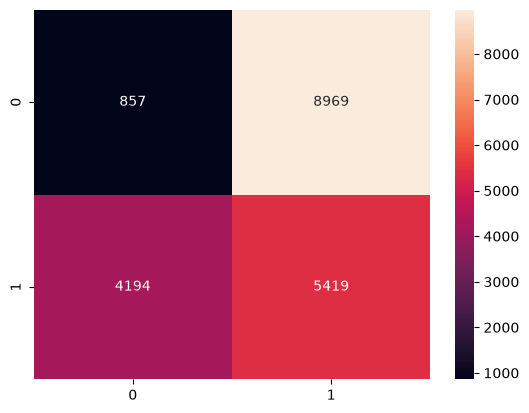

SVC accuracy is: 32.29%


In [25]:
from sklearn.svm import SVC
SVCclassifier = SVC(kernel='linear', max_iter=251)
SVCclassifier.fit(X_train, y_train)

y_pred = SVCclassifier.predict(X_test)

print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='.0f')
plt.show()

from sklearn.metrics import accuracy_score
SVCAcc = accuracy_score(y_pred,y_test)
print('SVC accuracy is: {:.2f}%'.format(SVCAcc*100))

## 4. Naive Bayes
### 4.1 Categorical NB

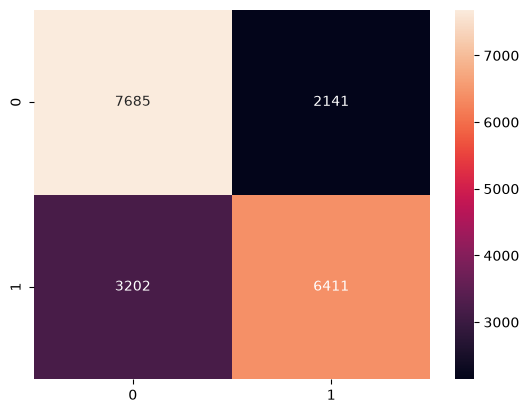

Naive Bayes accuracy is: 72.51%


In [26]:
from sklearn.naive_bayes import CategoricalNB
NBclassifier1 = CategoricalNB()
NBclassifier1.fit(X_train, y_train)

y_pred = NBclassifier1.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='.0f')
plt.show()

from sklearn.metrics import accuracy_score
NBAcc1 = accuracy_score(y_pred,y_test)
print('Naive Bayes accuracy is: {:.2f}%'.format(NBAcc1*100))

### 4.2 Gaussian NB

              precision    recall  f1-score   support

           0       0.66      0.83      0.73      9826
           1       0.76      0.55      0.64      9613

    accuracy                           0.69     19439
   macro avg       0.71      0.69      0.69     19439
weighted avg       0.71      0.69      0.69     19439



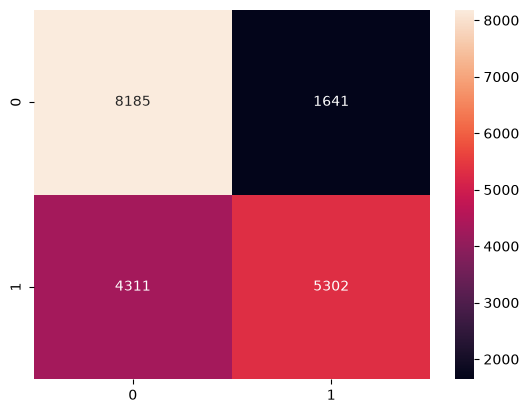

Gaussian Naive Bayes accuracy is: 69.38%


In [27]:
from sklearn.naive_bayes import GaussianNB
NBclassifier2 = GaussianNB()
NBclassifier2.fit(X_train, y_train)

y_pred = NBclassifier2.predict(X_test)

print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='.0f')
plt.show()

from sklearn.metrics import accuracy_score
NBAcc2 = accuracy_score(y_pred,y_test)
print('Gaussian Naive Bayes accuracy is: {:.2f}%'.format(NBAcc2*100))

## 5. Decision Tree

              precision    recall  f1-score   support

           0       0.69      0.83      0.75      9826
           1       0.78      0.63      0.70      9613

    accuracy                           0.73     19439
   macro avg       0.74      0.73      0.72     19439
weighted avg       0.74      0.73      0.73     19439



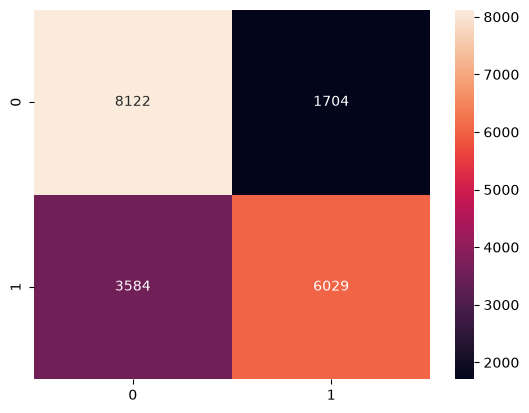

Decision Tree accuracy is: 72.80%


In [28]:
from sklearn.tree import DecisionTreeClassifier
DTclassifier = DecisionTreeClassifier(max_leaf_nodes=20)
DTclassifier.fit(X_train, y_train)

y_pred = DTclassifier.predict(X_test)

print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='.0f')
plt.show()

from sklearn.metrics import accuracy_score
DTAcc = accuracy_score(y_pred,y_test)
print('Decision Tree accuracy is: {:.2f}%'.format(DTAcc*100))

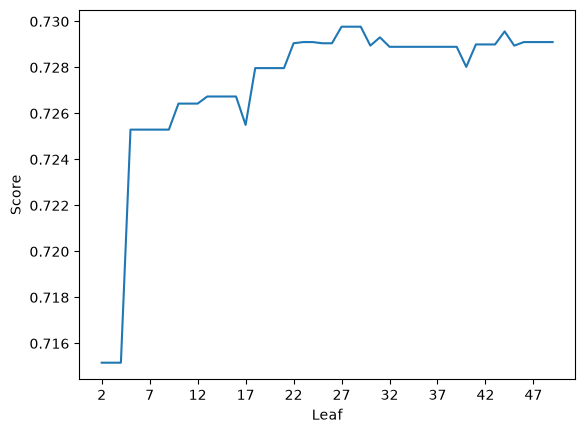

DT Acc Max 72.98%


In [29]:
scoreListDT = []
for i in range(2,50):
    DTclassifier = DecisionTreeClassifier(max_leaf_nodes=i)
    DTclassifier.fit(X_train, y_train)
    scoreListDT.append(DTclassifier.score(X_test, y_test))
    
plt.plot(range(2,50), scoreListDT)
plt.xticks(np.arange(2,50,5))
plt.xlabel("Leaf")
plt.ylabel("Score")
plt.show()
DTAccMax = max(scoreListDT)
print("DT Acc Max {:.2f}%".format(DTAccMax*100))

## 6. Random Forest

              precision    recall  f1-score   support

           0       0.71      0.78      0.75      9826
           1       0.75      0.67      0.71      9613

    accuracy                           0.73     19439
   macro avg       0.73      0.73      0.73     19439
weighted avg       0.73      0.73      0.73     19439



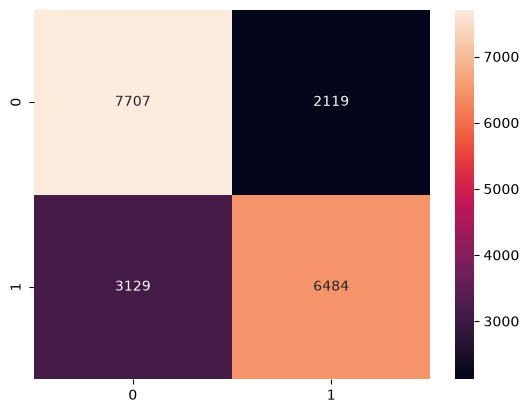

Random Forest accuracy is: 73.00%


In [30]:
from sklearn.ensemble import RandomForestClassifier

RFclassifier = RandomForestClassifier(max_leaf_nodes=30)
RFclassifier.fit(X_train, y_train)

y_pred = RFclassifier.predict(X_test)

print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='.0f')
plt.show()

from sklearn.metrics import accuracy_score
RFAcc = accuracy_score(y_pred,y_test)
print('Random Forest accuracy is: {:.2f}%'.format(RFAcc*100))

2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 

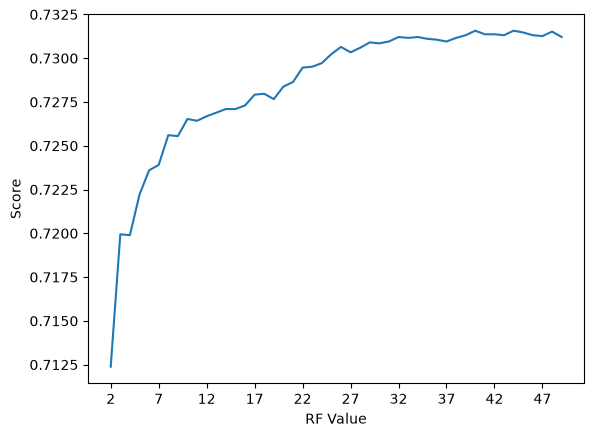

RF Acc Max 73.16%


In [31]:
scoreListRF = []
for i in range(2,50):
    RFclassifier = RandomForestClassifier(n_estimators = 1000, random_state = 1, max_leaf_nodes=i)
    RFclassifier.fit(X_train, y_train)
    scoreListRF.append(RFclassifier.score(X_test, y_test))
    print(i, end=" ") # to show that it is running
    
plt.plot(range(2,50), scoreListRF)
plt.xticks(np.arange(2,50,5))
plt.xlabel("RF Value")
plt.ylabel("Score")
plt.show()
RFAccMax = max(scoreListRF)
print("RF Acc Max {:.2f}%".format(RFAccMax*100))

# Model Comparison 👀

In [32]:
compare = pd.DataFrame({'Model': ['Logistic Regression', 'SVM', 'K Neighbors', 'K Neighbors Max', 
                                  'Categorical NB', 'Gaussian NB', 
                                  'Decision Tree', 'Decision Tree Max', 'Random Forest', 'Random Forest Max'], 
                        'Accuracy': [LRAcc*100, SVCAcc*100, KNAcc*100, KNAccMax*100, 
                                     NBAcc1*100, NBAcc2*100, 
                                     DTAcc*100, DTAccMax*100, RFAcc*100, RFAccMax*100]})
#compare.sort_values(by='Accuracy', ascending=False)
compare

,Model,Accuracy
0,Logistic Regression,72.261948
1,SVM,32.285611
2,K Neighbors,72.102474
3,K Neighbors Max,72.261948
4,Categorical NB,72.514018
5,Gaussian NB,69.381141
6,Decision Tree,72.796955
7,Decision Tree Max,72.977005
8,Random Forest,73.002726
9,Random Forest Max,73.157055


👉 From the results, it can be seen that most of ML models can reach **above 73% accuracy** in predicting classification of Heart disease.

<div style="height: 50px; background: linear-gradient(to right, lightblue, blue, darkblue);"></div>

# Save Model

In [33]:
import joblib

# Save the trained model
joblib.dump(RFclassifier, 'model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [34]:
# Load the saved model
model_load = joblib.load('model.pkl')

# Predict using the loaded model
y_pred = model_load.predict(X_test)

print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.71      0.79      0.75      9826
           1       0.76      0.67      0.71      9613

    accuracy                           0.73     19439
   macro avg       0.73      0.73      0.73     19439
weighted avg       0.73      0.73      0.73     19439



In [ ]:
#from keras.saving import save_model, load_model

#save_model(model, 'model.keras')  # Use save_model for saving

In [ ]:
#my_loaded_model = load_model('model.keras')
#my_loaded_model.predict(np.array([10]))

<div style="height: 50px; background: linear-gradient(to right, lightblue, blue, darkblue);"></div>

## Output 📤
👉 The next step will make output results in csv file.

## Transforming prediction in appropriate output format 🧹

## Generating output file (CSV) 📄

In [35]:
pred_lr = RFclassifier.predict(X_test)
pred_lr = pd.DataFrame({'disease': pred_lr})

X_test = X_test.reset_index(drop=True)
pred_lr = pred_lr.reset_index(drop=True)
prediction = pd.concat([X_test, pred_lr], axis=1)

prediction.to_csv('prediction.csv', index=False)
predictioncsv = pd.read_csv('./prediction.csv')
predictioncsv.head()


,active,age_group,alco,ap_hi,ap_lo,cholesterol,gender,gluc,height,smoke,...,occupation_Accountant,occupation_Architect,occupation_Chef,occupation_Doctor,occupation_Engineer,occupation_Lawyer,occupation_Nurse,occupation_Others,occupation_Teacher,disease
0,1,3,1,80,120,2,2,2,12.789176,1,...,False,False,False,False,False,True,False,False,False,1
1,1,3,0,150,90,0,2,0,13.398184,0,...,False,False,False,False,True,False,False,False,False,1
2,1,2,0,110,69,0,2,0,14.616201,0,...,False,True,False,False,False,False,False,False,False,0
3,1,3,0,120,60,0,2,0,14.250796,0,...,False,False,False,False,False,False,False,False,True,0
4,0,4,0,130,80,2,1,0,14.250796,0,...,True,False,False,False,False,False,False,False,False,1


<div style="height: 50px; background: linear-gradient(to right, #e9d5ff, #a855f7, #6b21a8);"></div>